# **Overlay**

This part of the book concerns calendar overlays. These, very loosely, are signals which act under certain market conditions, at certain calendar times, and move capital into different assets. This notebook concerns the cumulative overlay, similarly to the sleeves.

## Imports

In [1]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Contribution

Similarly to other notebooks, begin by showing the contribution the overlays have to the book.

In [2]:
sp.table("parts_stats.csv").query("part == 'overlay'").drop(columns="part").set_index("window")

,months,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,best_month_pp,worst_month_pp,sum_pp,correlation_with_core
window,,,,,,,,
full 2001-02–2026-09,308,1.652,3.691,0.447,5.291,-4.361,42.390,0.240
book 2006-01–2026-09,249,2.111,4.047,0.522,5.291,-4.361,43.798,0.249
2001-05,59,-0.286,1.290,-0.222,1.248,-1.024,-1.408,0.269
2006-13,96,1.570,2.601,0.604,3.903,-2.541,12.563,0.210
2014-19,72,2.232,4.298,0.519,3.719,-4.361,13.392,0.071
2020-26,81,2.643,5.128,0.515,5.291,-3.882,17.843,0.435


It is easy to see that the overlay is positive over most extended time periods, and contributes noticable Sharpe to the book

## Cumulative contribution

Below, see the plot that shows the cumulative monthly contribution of the overlays as a function of time

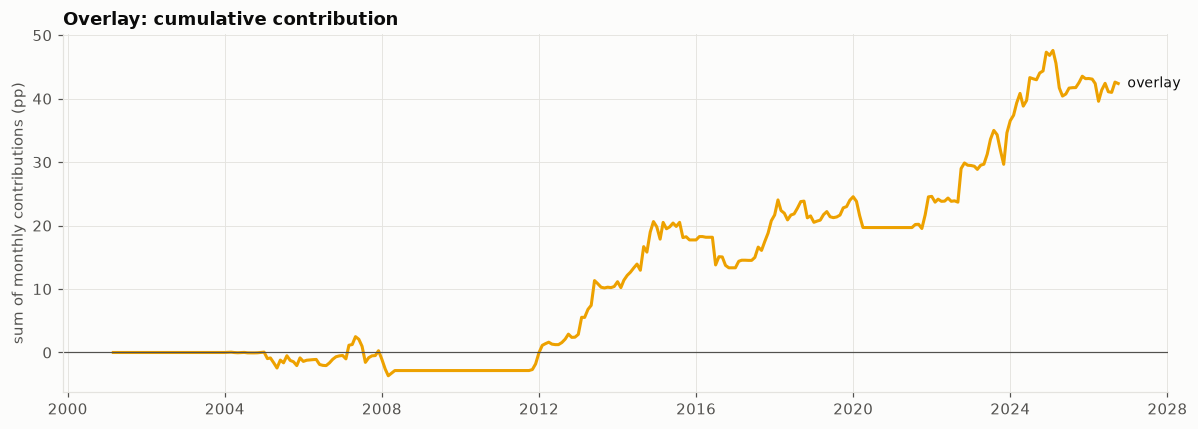

In [3]:
sp.lines({"overlay": 100 * d["overlay"].cumsum()}, sp.COLORS, "Overlay: cumulative contribution", "sum of monthly contributions (pp)")

It is easy to see that, the overlay does best in long, steady rises, such as 2013–14, 2017 and 2023–24, where it adds between 7 and 10% (pp) per year, and losses come mostly from short, sharp shocks after calm periods, such as 2007–08, 2018, 2020 and 2025. This same pattern can be seen below.

## By year


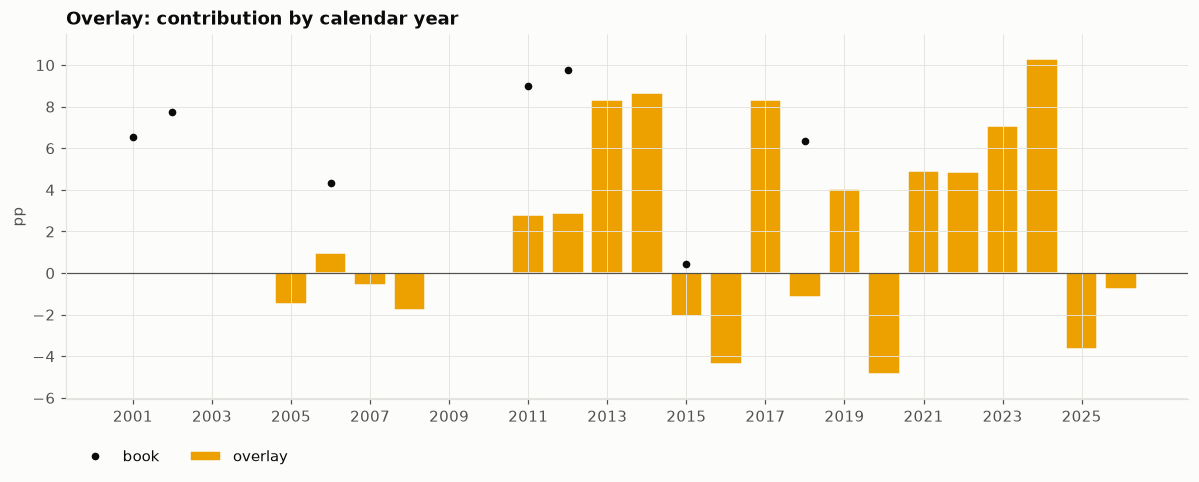

In [4]:
y = sp.table("parts_by_year.csv").set_index("year").rename(columns=lambda c: c.removesuffix("_pp"))
sp.year_bars(y, ["overlay"], "Overlay: contribution by calendar year", "pp")

## Before 2001

The first time the overlay can act is in 1988, due to unusable index history before that point

In [5]:
L = sp.long_parts()
t = sp.period_table(L, {"without overlay": "with_sleeves", "with overlay (book)": "book"})
print(f"Feb 1979 – Jan 2001, cash {t.attrs['cash']:.1f}% a year")
t.round(2)

Feb 1979 – Jan 2001, cash 10.2% a year


,CAGR %,vol %,Sharpe over cash,return / vol,max drawdown %,£10k becomes
without overlay,16.830,16.660,0.440,1.020,-31.370,"306,300.450"
with overlay (book),18.480,16.890,0.510,1.100,-31.370,"416,718.500"


In this era, the overlays together add to the book, taking it from 16.8% to 18.5% CAGR (Sharpe 0.44 to 0.51), but almost all of that comes from the steady rise of 1995–97. Outside those years the overlays detract. This is expected based on the economic foundation of the idea, one main overlay relies on something that began to occur in the mid-2000s, and the current use of such overlay is a regime-bet that this continues.